# 로지스틱 회귀분석(Logistic Regression)

- 선형회귀분석과 유사하지만 종속변수가 양적척도가 아닌 질적척도임
    - 특성 수치를 예측하는 것이 아니라 어떤 카테고리에 들어갈지 분류하는 모델
 
- 기본 모형은 종속변수가 0과 1이라는 이항(binary)으로 이루어져 구매/미구매, 성공/실패, 합격/불합격 등을 예측

- 만약 종속변수의 범주가 3개 이상일 경우에는 다항 로지스틱 회귀분석(Multinomial Logistic Regression) 을 통해 분류 예측을 할 수 있음

- 로지스틱 회귀는 기존의 선형회귀식의 사상은 그대로 유지하되 종속변수를 1이 될 확률로 변환하여 그 확률에 따라 0과 1의 여부를 예측

- 선형회귀선은 이항으로 이루어진 종속변수를 직선으로 표현하여 확률이 양과 음의 무한대로 뻗어나가게 됨
    - 이러한 방식은 확률을 표현하기에 적합하지 않기 때문에 0과 1사이의 S자 곡선의 형태를 갖도록 변환해줘야 함
 
- 선형회귀선을 로짓회귀선으로 변환하기 위해서는 오즈값을 구해야 함
    - 오즈(Odds) : 사건이 발생할 가능성이 발생하지 않을 가능성보다 어느 정도 큰지를 나타내는 값
        - 분모는 사건이 발생하지 않을 확률, 분자는 사건이 발생할 확률로 하여 사건이 발생하지 않을 확률 대비 사건이 발생할 확률을 비율로 나타냄
     
        - 즉, 발생할 확률이 그렇지 않을 확률과 50 : 50으로 같으면 1.0, 두 배면 2.0, 다섯 배면 5.0이 됨
     
        - 만약 발생확률이 60%이고 발생하지 않을 확률이 40%라면 발생확률이 1.5배 높기 때문에 오즈는 1.5가 됨
     
        - $$ \frac{p}{1-p} $$
     
    - 하지만 직선 형태의 회귀 값을 사건이 일어날 오즈값으로 변환하게 되면 발생확률이 1에 가까워질수록 기하급수적으로 커지고 최솟값은 0이 되는 균형잡히지 않은 형태가 됨

<img src = "./ML_전체이미지/odds.png">

- 따라서 오즈 값에 로그를 취하면 양의 무한대에서 음의 무한대를 갖는 형태가 됨
    - $$ \log\left(\frac{p}{1-p}\right) $$

- 하지만 여전히 0에서 1 사이의 범위를 나타내지 못하는 문제가 있음
    - 따라서 확률을 로짓 변환하여 0에서 1사이로 치환
 
    - 이 변환식을 시그모이드(Sigmoid) 함수라고 함
 
    - $$ \frac{1}{1 + e^{-x}} $$
        - 시그모이드 함수 적용 과정
            1. $$ \sigma\left(\log\left(\frac{p}{1-p}\right)\right) = \frac{1}{1 + e^{-\log\left(\frac{p}{1-p}\right)}} $$
            2. $$ e^{-\log\left(\frac{p}{1-p}\right)} = \frac{1}{e^{\log\left(\frac{p}{1-p}\right)}} = \frac{1}{\frac{p}{1-p}} $$
            3. $$ \frac{1}{1 + \frac{1-p}{p}} $$
            4. $$ \frac{1}{\frac{p + 1 - p}{p}} = \frac{p}{1} = p $$

- 이렇게 로지스틱 회귀분석은 사건 발생 확률을 0에서 1사이로 변환해서 표현
    - 이러한 분류 모델은 카테고리를 분류하는 임계치를 어떻게 설정하는지가 중요
        - 기본적으로 분류 기준값은 0.5
        - 주제에 따라 달라질 수 있음
    - 최적의 효율을 따져가며 분류 기준을 잡아야하기 때문에, 로지스틱 회귀 모델과 같은 분류 모델은 모델 성능평가가 매우 중요

In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from imblearn.under_sampling import RandomUnderSampler
import statsmodels.api as sm
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# 데이터 불러오기
df = pd.read_csv("./data/heart_2020_cleaned.csv")

In [3]:
df.head()

,HeartDisease,BMI,Smoking,AlcoholDrinking,Stroke,PhysicalHealth,MentalHealth,DiffWalking,Sex,AgeCategory,Race,Diabetic,PhysicalActivity,GenHealth,SleepTime,Asthma,KidneyDisease,SkinCancer
0,No,16.60,Yes,No,No,3.0,30.0,No,Female,55-59,White,Yes,Yes,Very good,5.0,Yes,No,Yes
1,No,20.34,No,No,Yes,0.0,0.0,No,Female,80 or older,White,No,Yes,Very good,7.0,No,No,No
2,No,26.58,Yes,No,No,20.0,30.0,No,Male,65-69,White,Yes,Yes,Fair,8.0,Yes,No,No
3,No,24.21,No,No,No,0.0,0.0,No,Female,75-79,White,No,No,Good,6.0,No,No,Yes
4,No,23.71,No,No,No,28.0,0.0,Yes,Female,40-44,White,No,Yes,Very good,8.0,No,No,No


In [4]:
df.shape

(319795, 18)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 319795 entries, 0 to 319794
Data columns (total 18 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   HeartDisease      319795 non-null  object 
 1   BMI               319795 non-null  float64
 2   Smoking           319795 non-null  object 
 3   AlcoholDrinking   319795 non-null  object 
 4   Stroke            319795 non-null  object 
 5   PhysicalHealth    319795 non-null  float64
 6   MentalHealth      319795 non-null  float64
 7   DiffWalking       319795 non-null  object 
 8   Sex               319795 non-null  object 
 9   AgeCategory       319795 non-null  object 
 10  Race              319795 non-null  object 
 11  Diabetic          319795 non-null  object 
 12  PhysicalActivity  319795 non-null  object 
 13  GenHealth         319795 non-null  object 
 14  SleepTime         319795 non-null  float64
 15  Asthma            319795 non-null  object 
 16  KidneyDisease     31

In [6]:
df.columns

Index(['HeartDisease', 'BMI', 'Smoking', 'AlcoholDrinking', 'Stroke',
       'PhysicalHealth', 'MentalHealth', 'DiffWalking', 'Sex', 'AgeCategory',
       'Race', 'Diabetic', 'PhysicalActivity', 'GenHealth', 'SleepTime',
       'Asthma', 'KidneyDisease', 'SkinCancer'],
      dtype='object')

In [7]:
# 명목형 변수 원핫인코딩
df2 = pd.get_dummies(df, columns = ["HeartDisease", "Smoking", 'AlcoholDrinking', 'Stroke',
                                    'DiffWalking', 'Sex', 'AgeCategory', 'Race', 'Diabetic',
                                    'PhysicalActivity', 'GenHealth', 'Asthma', 'KidneyDisease',
                                    'SkinCancer'], drop_first = True)

In [8]:
df2.head()

,BMI,PhysicalHealth,MentalHealth,SleepTime,HeartDisease_Yes,Smoking_Yes,AlcoholDrinking_Yes,Stroke_Yes,DiffWalking_Yes,Sex_Male,...,Diabetic_Yes,Diabetic_Yes (during pregnancy),PhysicalActivity_Yes,GenHealth_Fair,GenHealth_Good,GenHealth_Poor,GenHealth_Very good,Asthma_Yes,KidneyDisease_Yes,SkinCancer_Yes
0,16.60,3.0,30.0,5.0,False,True,False,False,False,False,...,True,False,True,False,False,False,True,True,False,True
1,20.34,0.0,0.0,7.0,False,False,False,True,False,False,...,False,False,True,False,False,False,True,False,False,False
2,26.58,20.0,30.0,8.0,False,True,False,False,False,True,...,True,False,True,True,False,False,False,True,False,False
3,24.21,0.0,0.0,6.0,False,False,False,False,False,False,...,False,False,False,False,True,False,False,False,False,True
4,23.71,28.0,0.0,8.0,False,False,False,False,True,False,...,False,False,True,False,False,False,True,False,False,False


In [9]:
df2.columns

Index(['BMI', 'PhysicalHealth', 'MentalHealth', 'SleepTime',
       'HeartDisease_Yes', 'Smoking_Yes', 'AlcoholDrinking_Yes', 'Stroke_Yes',
       'DiffWalking_Yes', 'Sex_Male', 'AgeCategory_25-29', 'AgeCategory_30-34',
       'AgeCategory_35-39', 'AgeCategory_40-44', 'AgeCategory_45-49',
       'AgeCategory_50-54', 'AgeCategory_55-59', 'AgeCategory_60-64',
       'AgeCategory_65-69', 'AgeCategory_70-74', 'AgeCategory_75-79',
       'AgeCategory_80 or older', 'Race_Asian', 'Race_Black', 'Race_Hispanic',
       'Race_Other', 'Race_White', 'Diabetic_No, borderline diabetes',
       'Diabetic_Yes', 'Diabetic_Yes (during pregnancy)',
       'PhysicalActivity_Yes', 'GenHealth_Fair', 'GenHealth_Good',
       'GenHealth_Poor', 'GenHealth_Very good', 'Asthma_Yes',
       'KidneyDisease_Yes', 'SkinCancer_Yes'],
      dtype='object')

In [10]:
# 스케일링
# 숫자형 변수 분리
df_num = df2[['BMI', 'PhysicalHealth', 'MentalHealth', 'SleepTime']]
df_nom = df2.drop(['BMI', 'PhysicalHealth', 'MentalHealth', 'SleepTime'], axis = 1)

In [11]:
# 숫자형 변수 RobustScaler 적용
rs = RobustScaler()
df_robust = rs.fit_transform(df_num)

In [12]:
df_num2 = pd.DataFrame(data = df_robust, columns = df_num.columns)

In [14]:
df_num.head()

,BMI,PhysicalHealth,MentalHealth,SleepTime
0,16.60,3.0,30.0,5.0
1,20.34,0.0,0.0,7.0
2,26.58,20.0,30.0,8.0
3,24.21,0.0,0.0,6.0
4,23.71,28.0,0.0,8.0


In [13]:
df_num2.head()

,BMI,PhysicalHealth,MentalHealth,SleepTime
0,-1.453315,1.5,10.0,-1.0
1,-0.947226,0.0,0.0,0.0
2,-0.102842,10.0,10.0,0.5
3,-0.423545,0.0,0.0,-0.5
4,-0.491204,14.0,0.0,0.5


In [15]:
# 숫자형 테이블과 더미화 문자형 테이블 결합
df3 = pd.concat([df_num2, df_nom], axis = 1)

In [16]:
df3.head()

,BMI,PhysicalHealth,MentalHealth,SleepTime,HeartDisease_Yes,Smoking_Yes,AlcoholDrinking_Yes,Stroke_Yes,DiffWalking_Yes,Sex_Male,...,Diabetic_Yes,Diabetic_Yes (during pregnancy),PhysicalActivity_Yes,GenHealth_Fair,GenHealth_Good,GenHealth_Poor,GenHealth_Very good,Asthma_Yes,KidneyDisease_Yes,SkinCancer_Yes
0,-1.453315,1.5,10.0,-1.0,False,True,False,False,False,False,...,True,False,True,False,False,False,True,True,False,True
1,-0.947226,0.0,0.0,0.0,False,False,False,True,False,False,...,False,False,True,False,False,False,True,False,False,False
2,-0.102842,10.0,10.0,0.5,False,True,False,False,False,True,...,True,False,True,True,False,False,False,True,False,False
3,-0.423545,0.0,0.0,-0.5,False,False,False,False,False,False,...,False,False,False,False,True,False,False,False,False,True
4,-0.491204,14.0,0.0,0.5,False,False,False,False,True,False,...,False,False,True,False,False,False,True,False,False,False


In [22]:
# 독립변수와 종속변수 분리
x = df3.drop(["HeartDisease_Yes"], axis = 1)
y = df3[["HeartDisease_Yes"]]

In [23]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.25, stratify = y,
                                                    random_state = 26)

In [24]:
x_train.shape, x_test.shape

((239846, 37), (79949, 37))

In [25]:
df3["HeartDisease_Yes"].value_counts()

HeartDisease_Yes
False    292422
True      27373
Name: count, dtype: int64

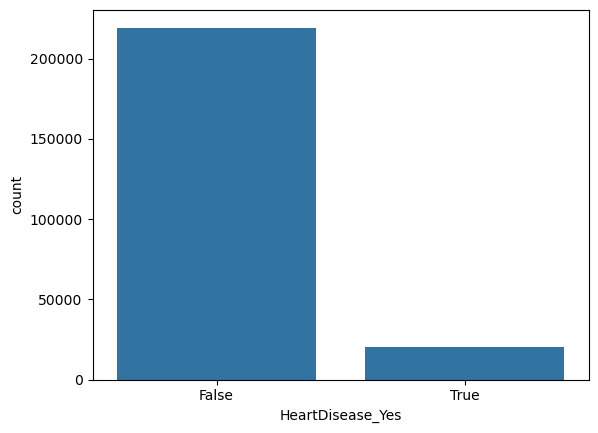

In [26]:
# HeartDisease_Yes 컬럼 클래스 분포 시각화
sns.countplot(data = y_train, x = "HeartDisease_Yes")
plt.show()

- 클래스 불균형이 심한 상황
    - 언더 샘플링이나 오버 샘플링을 적용하여 클래스 균형을 맞춰 줘야 함

In [27]:
# 임시 변수명 적용
x_train_re = x_train.copy()
y_train_re = y_train.copy()

In [28]:
x_train.shape

(239846, 37)

In [33]:
x_temp_name = [f"X{i}" for i in range(1, 38)]

In [34]:
y_temp_name = ["y1"]

In [35]:
x_train_re.columns = x_temp_name
y_train_re.columns = y_temp_name

In [36]:
x_train_re.head()

,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,X28,X29,X30,X31,X32,X33,X34,X35,X36,X37
53053,-0.209743,0.0,0.000000,0.5,True,False,False,False,False,False,...,False,False,True,False,False,False,False,False,False,False
248103,-0.270636,0.0,0.000000,0.5,True,False,False,True,False,False,...,False,False,True,False,False,False,True,False,False,True
76889,0.377537,0.0,0.000000,0.0,True,False,False,False,True,False,...,True,False,True,False,False,False,False,False,False,False
68266,-0.343708,0.0,9.666667,0.5,False,False,False,True,False,False,...,False,False,False,False,True,False,False,False,False,True
41404,-0.652233,0.0,0.333333,0.0,True,False,False,False,False,False,...,False,False,True,False,True,False,False,True,False,False


- 기존 변수명은 언더샘플링이나 오버샘플링 적용 시 오류가 발생하기 때문에 임시 변수명을 부여

In [37]:
# 언더샘플링 적용
x_train_under, y_train_under = RandomUnderSampler(random_state = 26).fit_resample(x_train_re,
                                                                                  y_train_re)

In [38]:
print("언더샘플링 적용전")
print(x_train_re.shape, y_train_re.shape)

언더샘플링 적용전
(239846, 37) (239846, 1)


In [39]:
print("언더샘플링 적용후")
print(x_train_under.shape, y_train_under.shape)

언더샘플링 적용후
(41060, 37) (41060, 1)


In [40]:
print("언더샘플링 적용전 종속변수 분포")
print(y_train_re["y1"].value_counts())

언더샘플링 적용전 종속변수 분포
y1
False    219316
True      20530
Name: count, dtype: int64


In [42]:
print("언더샘플링 적용후 종속변수 분포")
print(y_train_under["y1"].value_counts())

언더샘플링 적용후 종속변수 분포
y1
False    20530
True     20530
Name: count, dtype: int64


- 클래스 불균형 문제를 해결하기 위해 언더샘플링을 적용

In [45]:
# 컬럼명 복구
x_train_under.columns = x_train.columns
y_train_under.columns = y_train.columns

In [46]:
x_train_under.head()

,BMI,PhysicalHealth,MentalHealth,SleepTime,Smoking_Yes,AlcoholDrinking_Yes,Stroke_Yes,DiffWalking_Yes,Sex_Male,AgeCategory_25-29,...,Diabetic_Yes,Diabetic_Yes (during pregnancy),PhysicalActivity_Yes,GenHealth_Fair,GenHealth_Good,GenHealth_Poor,GenHealth_Very good,Asthma_Yes,KidneyDisease_Yes,SkinCancer_Yes
174516,-0.158322,0.0,0.000000,-0.5,False,False,False,False,True,False,...,False,False,True,False,False,False,False,False,False,False
14280,-0.399188,0.0,0.666667,-3.0,False,False,False,False,True,True,...,False,False,True,False,False,False,False,True,False,False
35183,-0.496617,0.0,0.000000,-0.5,True,False,False,False,True,False,...,False,False,True,False,False,False,False,False,False,False
29111,0.433018,0.0,0.000000,0.0,True,False,False,False,True,False,...,False,False,True,False,False,False,True,False,False,False
258612,-1.056834,0.0,1.666667,0.5,True,False,False,False,False,False,...,False,False,True,False,False,False,True,False,False,False


In [47]:
x_train_under.shape

(41060, 37)

In [48]:
x_test.shape

(79949, 37)

In [49]:
# 모델 학습
logi = LogisticRegression()
logi.fit(x_train_under, y_train_under)

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:1300: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [51]:
print(logi.score(x_train_under, y_train_under))
print(logi.score(x_test, y_test))

0.7644179249878227
0.7494903000662922


In [52]:
# 계수값 확인
print(logi.coef_)

[[ 0.07812679  0.0074099   0.01517354 -0.05698809  0.37296029 -0.18396566
   1.25705057  0.30254747  0.74117717 -0.11364318  0.1375774   0.32507718
   0.74856923  0.92766628  1.34930281  1.69041698  1.94715393  2.19164219
   2.50928999  2.70768367  3.05910533 -0.76368448 -0.50568595 -0.29406839
  -0.26922156 -0.25808589  0.2043201   0.51937681  0.27661668  0.03025086
   1.52578415  1.03761583  1.91997427  0.43381892  0.29534957  0.58444021
   0.14760436]]


In [57]:
x_train_under = x_train_under.astype(float)

In [58]:
# statsmodels 라이브러리로 로지스틱 모델 학습
logi2 = sm.Logit(y_train_under, x_train_under)
result = logi2.fit()

Optimization terminated successfully.
         Current function value: 0.501118
         Iterations 7


In [59]:
result.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:       HeartDisease_Yes   No. Observations:                41060
Model:                          Logit   Df Residuals:                    41023
Method:                           MLE   Df Model:                           36
Date:                Tue, 08 Apr 2025   Pseudo R-squ.:                  0.2770
Time:                        16:14:53   Log-Likelihood:                -20576.
converged:                       True   LL-Null:                       -28461.
Covariance Type:            nonrobust   LLR p-value:                     0.000
====================================================================================================
                                       coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------
BMI                                  0.0875      0.015      5.745      0.000       0.058       0.117
PhysicalHealth                       0.0061      0.003      1.800      0.072      -0.001       0.013
MentalHealth                         0.0060      0.005      1.232      0.218      -0.004       0.016
SleepTime                           -0.0685      0.016     -4.294      0.000      -0.100      -0.037
Smoking_Yes                          0.3491      0.025     13.926      0.000       0.300       0.398
AlcoholDrinking_Yes                 -0.2103      0.054     -3.920      0.000      -0.315      -0.105
Stroke_Yes                           1.2455      0.054     23.122      0.000       1.140       1.351
DiffWalking_Yes                      0.2768      0.035      7.923      0.000       0.208       0.345
Sex_Male                             0.6604      0.025     26.151      0.000       0.611       0.710
AgeCategory_25-29                   -1.2718      0.121    -10.500      0.000      -1.509      -1.034
AgeCategory_30-34                   -1.0309      0.106     -9.734      0.000      -1.238      -0.823
AgeCategory_35-39                   -0.7927      0.098     -8.073      0.000      -0.985      -0.600
AgeCategory_40-44                   -0.3993      0.088     -4.558      0.000      -0.571      -0.228
AgeCategory_45-49                   -0.2083      0.083     -2.514      0.012      -0.371      -0.046
AgeCategory_50-54                    0.2247      0.076      2.958      0.003       0.076       0.374
AgeCategory_55-59                    0.5714      0.072      7.912      0.000       0.430       0.713
AgeCategory_60-64                    0.8346      0.070     11.878      0.000       0.697       0.972
AgeCategory_65-69                    1.0866      0.070     15.569      0.000       0.950       1.223
AgeCategory_70-74                    1.4010      0.070     20.013      0.000       1.264       1.538
AgeCategory_75-79                    1.6055      0.073     22.005      0.000       1.462       1.748
AgeCategory_80 or older              1.9325      0.072     26.795      0.000       1.791       2.074
Race_Asian                          -2.8188      0.120    -23.489      0.000      -3.054      -2.584
Race_Black                          -2.5332      0.082    -30.848      0.000      -2.694      -2.372
Race_Hispanic                       -2.3760      0.080    -29.777      0.000      -2.532      -2.220
Race_Other                          -2.3096      0.094    -24.455      0.000      -2.495      -2.125
Race_White                          -2.2849      0.069    -32.988      0.000      -2.421      -2.149
Diabetic_No, borderline diabetes     0.2084      0.076      2.734      0.006       0.059       0.358
Diabetic_Yes                         0.5127      0.032     15.777      0.000       0.449       0.576
Diabetic_Yes (during pregnancy)      0.1185      0.164      0.724      0.469      -0.203       0.440
PhysicalA

In [60]:
# 로지스틱 회귀의 오즈비 확인
np.exp(logi.coef_)

array([[ 1.08125975,  1.00743742,  1.01528924,  0.94460532,  1.45202668,
         0.83196437,  3.51503881,  1.35330192,  2.09840424,  0.89257638,
         1.14749052,  1.38413747,  2.11397325,  2.52860123,  3.85473713,
         5.42174098,  7.00871188,  8.9498985 , 12.29619652, 14.99450298,
        21.30848459,  0.46594649,  0.60309174,  0.74522552,  0.76397397,
         0.77252887,  1.22669075,  1.68097975,  1.3186608 ,  1.03071307,
         4.59874827,  2.82247972,  6.82078298,  1.54313941,  1.34359596,
         1.79398644,  1.15905424]])

In [62]:
np.exp(result.params)

BMI                                 1.091441
PhysicalHealth                      1.006121
MentalHealth                        1.006039
SleepTime                           0.933777
Smoking_Yes                         1.417739
AlcoholDrinking_Yes                 0.810364
Stroke_Yes                          3.474693
DiffWalking_Yes                     1.318931
Sex_Male                            1.935521
AgeCategory_25-29                   0.280313
AgeCategory_30-34                   0.356682
AgeCategory_35-39                   0.452601
AgeCategory_40-44                   0.670761
AgeCategory_45-49                   0.811976
AgeCategory_50-54                   1.251915
AgeCategory_55-59                   1.770812
AgeCategory_60-64                   2.303926
AgeCategory_65-69                   2.964116
AgeCategory_70-74                   4.059246
AgeCategory_75-79                   4.980195
AgeCategory_80 or older             6.906429
Race_Asian                          0.059679
Race_Black

- 독립변수가 종속변수의 심장병 여부 확률에 어떤 영향을 미치는지 확인하기 위해 오즈비를 산출
    - 해당 독립변수가 1일 때 심장병 발생 확률이 몇 배 더 큰지를 나타냄
    - 예) Smoking_Yes변수의 오즈비는 1.4 이기 때문에 흡연자는 비흡연자보다 심장병 발생 확률이 1.4배 높다